# py-Pando tutorial: gene regulatory networks from 10x multiome PBMCs

**What this package does.** [Pando](https://github.com/quadbio/Pando) (Fleck *et al.*, *Nature* 2023) infers gene regulatory networks from paired single-cell RNA and ATAC: for every target gene it regresses expression on *TF expression x accessibility of TF-binding peaks near the gene*, and reads significant terms as TF → region → gene links; TFs with many links form modules. py-Pando is a pure-Python port, parity-tested against R Pando 1.1.1 (see `compare_R_vs_Python.ipynb`).

**Input.** RNA as an AnnData (cells x genes, log-normalised like Seurat's `LogNormalize`), ATAC as an AnnData (cells x peaks, TF-IDF like Signac's `RunTFIDF`, peak names `chr-start-end`), a gene annotation and a genome FASTA. **Output.** A `GRNData` holding the candidate regions, motif matches, one network per inference run (coefficients, goodness of fit) and TF modules.

## Install and import

```bash
pip install pypando 'pypando[xgb,umap]'
```

In [1]:
import os
from pathlib import Path

import anndata as ad
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pooch
import scipy.sparse as sp

import pypando as pp
from pypando.formula import PandoFormula

DATA = Path(os.environ.get("PYPANDO_DATA_DIR", pooch.os_cache("pypando")))
print(pp.__version__)

0.1.0


## Load demo data

10x Genomics Multiome PBMC 10k (granulocytes removed), with the GENCODE v41 GRCh38 genome and basic annotation. For speed the tutorial uses 2,000 cells and 150 target genes; the parity notebook uses the same sample.

In [2]:
h5 = pooch.retrieve(
    "https://cf.10xgenomics.com/samples/cell-arc/2.0.0/pbmc_granulocyte_sorted_10k/"
    "pbmc_granulocyte_sorted_10k_filtered_feature_bc_matrix.h5",
    known_hash="sha256:f6824171378787baab244f559b8b438f79db2eb39f78d17b2196f7ecd2c03549",
    path=DATA, fname="pbmc_granulocyte_sorted_10k_filtered_feature_bc_matrix.h5", progressbar=False)
fasta = pooch.retrieve(
    "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_41/GRCh38.primary_assembly.genome.fa.gz",
    known_hash="sha256:4fac949d7021cbe11117ddab8ec1960004df423d672446cadfbc8cca8007e228",
    path=DATA, fname="gencode_v41_GRCh38.fa.gz", processor=pooch.Decompress(method="gzip"), progressbar=False)
gff = pooch.retrieve(
    "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_41/gencode.v41.basic.annotation.gff3.gz",
    known_hash="sha256:b82a655bdb736ca0e463a8f5d00242bedf10fa88ce9d651a017f135c7c4e9285",
    path=DATA, fname="gencode_v41_GRCh38.gff3.gz", progressbar=False)

with h5py.File(h5) as f:
    m = f["matrix"]
    X = sp.csc_matrix((m["data"][:], m["indices"][:], m["indptr"][:]), shape=tuple(m["shape"][:])).T.tocsr()
    barcodes = m["barcodes"][:].astype(str)
    names = m["features/name"][:].astype(str)
    ftype = m["features/feature_type"][:].astype(str)
cells = np.sort(np.random.default_rng(42).choice(X.shape[0], 2000, replace=False))
X = X[cells]
gex, pk = ftype == "Gene Expression", ftype == "Peaks"
rna = ad.AnnData(X[:, gex].astype(float), obs=pd.DataFrame(index=barcodes[cells]), var=pd.DataFrame(index=names[gex]))
rna.var_names_make_unique()
atac = ad.AnnData(X[:, pk].astype(float), obs=pd.DataFrame(index=barcodes[cells]),
                  var=pd.DataFrame(index=[p.replace(":", "-") for p in names[pk]]))
print(rna, atac, sep="\n")

pyenv/lib/python3.11/site-packages/anndata/_core/anndata.py:1884: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


AnnData object with n_obs × n_vars = 2000 × 36601
AnnData object with n_obs × n_vars = 2000 × 143887


**Normalisation as Pando expects it.** Pando reads the `data` layers of a Seurat object: `LogNormalize` for RNA (`log1p(count / cell total x 1e4)`) and Signac's TF-IDF for peaks (`log1p(count / cell total x n_cells / peak total x 1e4)`).

In [3]:
def lognormalize(M):
    tot = np.asarray(M.sum(1)).ravel()
    out = sp.csr_matrix(sp.diags(1 / tot) @ M); out.data = np.log1p(out.data * 1e4); return out

def tfidf(M):
    tot = np.asarray(M.sum(1)).ravel(); idf = M.shape[0] / np.asarray(M.sum(0)).ravel()
    out = sp.csr_matrix(sp.diags(1 / tot) @ M @ sp.diags(idf)); out.data = np.log1p(out.data * 1e4); return out

rna.X = lognormalize(rna.X)
atac.X = tfidf(atac.X)

/tmp/ipykernel_54283/2913551426.py:6: RuntimeWarning: divide by zero encountered in divide
  tot = np.asarray(M.sum(1)).ravel(); idf = M.shape[0] / np.asarray(M.sum(0)).ravel()


## `annotation_from_gtf` — gene annotation

Builds the table Signac's `GetGRangesFromEnsDb` gives Pando (exon / CDS / UTR rows of protein-coding and lncRNA genes).

R: `annot <- GetGRangesFromEnsDb(EnsDb.Hsapiens.v86)`

In [4]:
annot = pp.annotation_from_gtf(gff)
print(annot.shape)
annot.head()

(1613688, 9)


,seqnames,start,end,strand,tx_id,gene_name,gene_id,gene_biotype,type
0,chr1,29554,30039,+,ENST00000473358,MIR1302-2HG,ENSG00000243485,lncRNA,exon
1,chr1,30564,30667,+,ENST00000473358,MIR1302-2HG,ENSG00000243485,lncRNA,exon
2,chr1,30976,31097,+,ENST00000473358,MIR1302-2HG,ENSG00000243485,lncRNA,exon
3,chr1,30267,30667,+,ENST00000469289,MIR1302-2HG,ENSG00000243485,lncRNA,exon
4,chr1,30976,31109,+,ENST00000469289,MIR1302-2HG,ENSG00000243485,lncRNA,exon


Target genes: the 150 most variable genes (variance of log-normalised expression) that have an annotation.

In [5]:
var = np.asarray(rna.X.power(2).mean(0)).ravel() - np.asarray(rna.X.mean(0)).ravel() ** 2
order = rna.var_names[np.argsort(-var)]
annotated = set(annot["gene_name"])
targets = [g for g in order if g in annotated][:150]
targets[:10]

['SAT1',
 'ZEB2',
 'AOAH',
 'CD74',
 'PLXDC2',
 'SLC8A1',
 'VCAN',
 'NEAT1',
 'BACH2',
 'LYN']

## `initiate_grn` — candidate regions

Peaks minus exons (optionally intersected with conserved elements or cCREs via `regions=`).

R: `grn <- initiate_grn(seurat_object)`

In [6]:
grn = pp.initiate_grn(rna, atac, annot, variable_features=targets)
print(pp.NetworkRegions(grn))
pp.NetworkRegions(grn).ranges.head()

A Regions object
with 164283 candidate genomic regions in 140366 peaks


,seqnames,start,end,strand
0,chr1,9790,10675,*
1,chr1,180599,181702,*
2,chr1,191168,192093,*
3,chr1,267565,268121,*
4,chr1,270876,271770,*


## `regions_near_genes`, `region_background`, `subset_regions` — scan only what the models can use (new in Python)

Pando scans every candidate region. Only regions a target gene can reach are ever used, so scanning those against the base composition of *all* regions gives exactly the same motif calls for them (each region is scanned independently given the background).

In [7]:
bg = pp.region_background(grn, fasta)
keep = pp.regions_near_genes(grn, targets, upstream=100000)
print("background A/C/G/T:", np.round(bg, 4), "| regions kept:", keep.sum(), "of", len(keep))
pp.subset_regions(grn, keep);

background A/C/G/T: [0.2655 0.2343 0.2346 0.2655] | regions kept: 7395 of 164283


## `find_motifs` — TF binding sites

Pando's bundled 1,590 motifs (JASPAR 2020 + CIS-BP), MOODS scan at p < 5e-5.

R: `grn <- find_motifs(grn, pfm = motifs, genome = BSgenome.Hsapiens.UCSC.hg38)`

1,158,767 region-motif matches; 1136 TFs expressed
CPU times: user 48.5 s, sys: 171 ms, total: 48.6 s
Wall time: 48.7 s


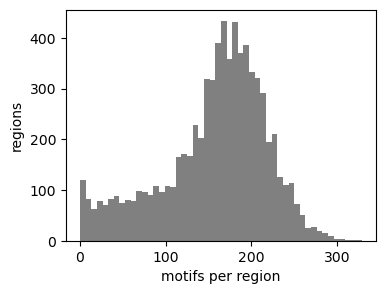

In [8]:
%%time
grn = pp.find_motifs(grn, genome=fasta, bg=bg, verbose=False)
m = pp.NetworkRegions(grn).motifs
print(f"{m.data.nnz:,} region-motif matches; {pp.NetworkTFs(grn).shape[1]} TFs expressed")
fig, ax = plt.subplots(figsize=(4, 3))
ax.hist(np.asarray(m.data.sum(1)).ravel(), bins=50, color="grey"); ax.set_xlabel("motifs per region"); ax.set_ylabel("regions");

## `find_peaks_near_genes` — region-to-gene windows

`Signac`: gene body + 100 kb upstream; `GREAT`: basal domain, then gene body, then 1 Mb extension.

R: `find_peaks_near_genes(peaks, genes, method = 'Signac')`

In [9]:
genes = annot[annot["gene_name"].isin(targets)]
for method in ("Signac", "GREAT"):
    hits, peak_names, gene_names = pp.find_peaks_near_genes(pp.NetworkRegions(grn).ranges, genes, method=method)
    per_gene = pd.Series(np.asarray(hits.sum(0)).ravel(), index=gene_names).groupby(level=0).sum()
    print(f"{method}: median {per_gene.median():.0f} regions per gene")

Signac: median 948 regions per gene


GREAT: median 442 regions per gene


## `infer_grn` — one model per target gene

Default: Gaussian glm with `peak:TF` terms, peaks with a motif in the gene's window, TFs with |cor| > 0.1.

R: `grn <- infer_grn(grn, genes = targets)`

In [10]:
%%time
grn = pp.infer_grn(grn, genes=targets, method="glm", verbose=False)
coefs, fit = pp.coef(grn), pp.gof(grn)
print(f"{len(fit)} genes, {len(coefs):,} terms, {(coefs.padj < 0.05).sum()} at FDR < 0.05")
coefs.sort_values("padj").head()

150 genes, 85,955 terms, 95 at FDR < 0.05
CPU times: user 2min 1s, sys: 1.32 s, total: 2min 2s
Wall time: 2min 2s


,tf,target,region,term,estimate,std_err,statistic,pval,padj,corr
528,FOSB,JUN,chr1-58784048-58784269,chr1_58784048_58784269:FOSB,0.599725,0.068876,8.707276,6.786300e-18,3.948205e-15,0.447307
38082,KLF4,NAMPT,chr7-106284705-106284827,chr7_106284705_106284827:KLF4,0.799798,0.103819,7.703758,2.318533e-14,1.330915e-11,0.669675
7406,IRF8,AFF3,chr2-100110382-100111273,IRF8:chr2_100110382_100111273,0.413711,0.058772,7.039233,2.824893e-12,1.610844e-09,0.266662
31288,ZEB2,RPL10A,chr6-35468440-35468798,ZEB2:chr6_35468440_35468798,-0.360394,0.060552,-5.951814,3.263809e-09,1.836535e-06,-0.528723
3248,NR3C2,S100A4,chr1-153633664-153633957,NR3C2:chr1_153633664_153633957,-0.346466,0.058269,-5.945991,3.284668e-09,1.836535e-06,-0.161026


## `plot_gof` — model fit

R: `plot_gof(grn)`

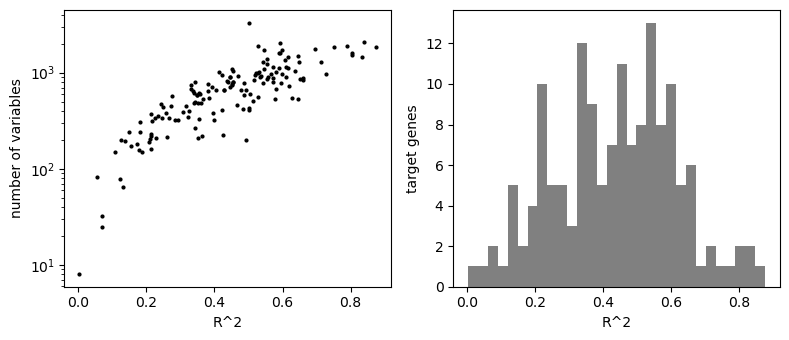

In [11]:
fig = pp.plot_gof(grn); fig.tight_layout()

## Other models (`method=`)

`glmnet` and `cv.glmnet` (elastic net; cv folds drawn from R's stream after `set.seed(seed)`), `xgb` (gradient boosting, gain importance), `bagging_ridge` and `bayesian_ridge` (scikit-learn, as Pando calls it). Shown on 15 genes; each run is stored as its own network.

R: `infer_grn(grn, genes = targets, method = 'cv.glmnet')`

In [12]:
few = targets[:15]
rows = []
for method in ("glmnet", "cv.glmnet", "xgb", "bagging_ridge", "bayesian_ridge"):
    pp.infer_grn(grn, genes=few, method=method, seed=42, verbose=False)
    g = pp.gof(grn)
    rows.append({"method": method, "genes": len(g), "median rsq": g["rsq"].median(), "terms": len(pp.coef(grn))})
print(list(grn.grn.networks))
pd.DataFrame(rows)

['glm_network', 'glmnet_network', 'cv.glmnet_network', 'xgb_network', 'bagging_ridge_network', 'bayesian_ridge_network']


,method,genes,median rsq,terms
0,glmnet,15,0.551868,14792
1,cv.glmnet,15,0.374601,14792
2,xgb,15,0.524505,3604
3,bagging_ridge,15,0.061017,14792
4,bayesian_ridge,15,0.452600,14792


## `find_modules` — TF modules

Significant positive / negative links per TF, from models with R² > 0.1 and > 10 variables.

R: `grn <- find_modules(grn)`

In [13]:
grn = pp.find_modules(grn, network="glm_network", verbose=False)
mods = pp.NetworkModules(grn, network="glm_network")
print(mods)
mods.meta.head()

An Modules object with 0 TF modules


,tf,target,estimate,n_regions,n_genes,n_tfs,regions,pval,padj
0,ASCL2,NKG7,0.633171,2,1,4,chr19-51441375-51442267,3.648113e-05,0.014747
1,ATF5,GAB2,1.142984,2,1,2,chr11-78289977-78290827,5.665828e-05,0.021696
2,BACH1,CCL5,-0.602827,5,1,7,chr17-35900279-35901216,8.632335e-07,0.000442
3,BCL11A,AFF3,0.327144,2,1,2,chr2-100142591-100143066,1.494734e-06,0.000757
4,BCL11B,RPL5,0.211502,1,1,1,chr1-92831645-92832039,1.845651e-07,0.000098


## `plot_module_metrics`

R: `plot_module_metrics(grn)`

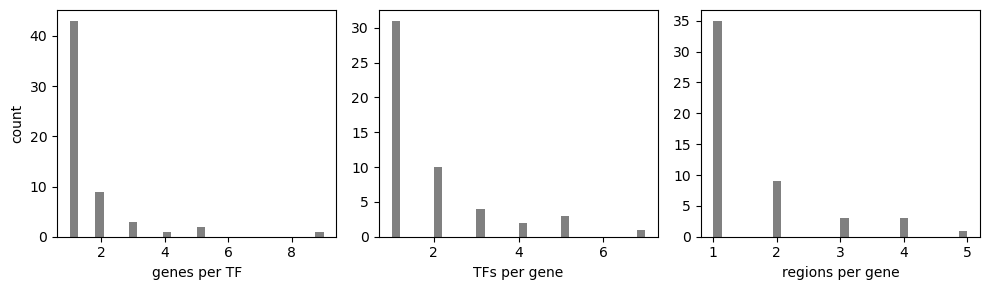

In [14]:
fig = pp.plot_module_metrics(grn, network='glm_network')

## `get_network_graph`, `plot_network_graph` — module graph

TF → target edges with PageRank; genes laid out by UMAP on regulation-weighted co-expression (umap-learn).

R: `grn <- get_network_graph(grn); plot_network_graph(grn)`

pyenv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,name,centrality,UMAP_1,UMAP_2
1,JUN,0.171055,-7.315316,1.957284
3,MEF2C,0.162977,-8.026528,2.830358
9,CD36,0.046347,-8.425140,1.558535
4,TCF7,0.042842,-14.215014,-3.381133
5,CCL5,0.032524,-14.112989,-1.762604


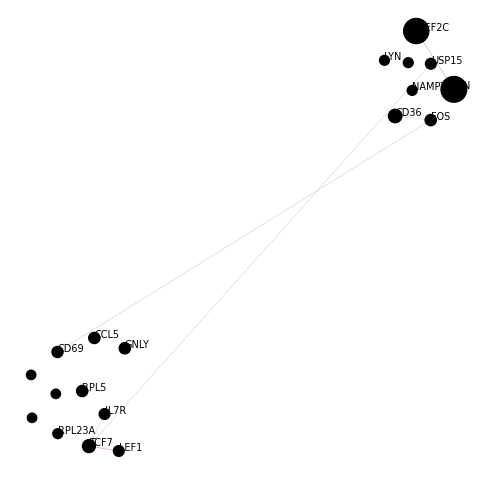

In [15]:
pp.get_network_graph(grn, network="glm_network", umap_method="weighted")
ax = pp.plot_network_graph(grn, network="glm_network")
pp.NetworkGraph(grn, network="glm_network")["nodes"].nlargest(5, "centrality")

## Accessors

`coef`, `gof`, `GetNetwork`, `DefaultNetwork`, `NetworkFeatures`, `NetworkParams`, `NetworkTFs`, `NetworkRegions`, `GetGRN`, `Params` — as in R.

In [16]:
print(pp.DefaultNetwork(grn), pp.NetworkParams(grn, "glm_network"))
print(len(pp.NetworkFeatures(grn, "glm_network")), "features;", pp.Params(grn))
pp.GetNetwork(grn, "glm_network")

bayesian_ridge_network {'method': 'glm', 'family': 'gaussian', 'dist': {'upstream': 100000, 'downstream': 0}, 'only_tss': False, 'interaction': ':', 'tf_cor': 0.1, 'peak_cor': 0.0}
150 features; {'peak_assay': 'peaks', 'rna_assay': 'RNA', 'exclude_exons': True}


A Network object
with 59 TFs and 51 target genes

## `fit_model` and the per-method fits on one design

The building blocks `infer_grn` calls for each gene. A formula in Pando's form can be written as in R with `PandoFormula.from_string`.

R: `fit_model(GENE ~ chr1_100_600:TFA + ..., data = df, method = 'glm')`

In [17]:
g = fit.sort_values("nvariables").iloc[len(fit) // 2]["target"]
sub = coefs[coefs.target == g]
terms = " + ".join(f"{r.replace('-', '_')}:{t.replace('-', '_')}" for r, t in zip(sub.region, sub.tf))
frm = PandoFormula.from_string(f"{g.replace('-', '_')} ~ {terms}")
cols = {v for p in frm.pairs for v in p} | {frm.target}
regs = pp.NetworkRegions(grn)
from pypando import ranges as R
reg2peak = {r.replace("-", "_"): pk for r, pk in zip(R.ranges_to_string(regs.ranges), atac.var_names[regs.peaks])}
data = {}
for v in cols:
    if v in rna.var_names or v.replace("_", "-") in rna.var_names:
        name = v if v in rna.var_names else v.replace("_", "-")
        data[v] = rna[:, name].X.toarray().ravel()
    else:  # a candidate region: its values are those of the peak it lies in
        data[v] = atac[:, reg2peak[v]].X.toarray().ravel()
for method in ("glm", "glmnet", "bayesian_ridge"):
    res = pp.fit_model(frm, data, method=method, alpha=0.5)
    print(method, "rsq =", round(res["gof"]["rsq"], 4), "|", len(res["coefs"]), "coefficients")

glm rsq = 0.4929 | 630 coefficients


glmnet rsq = 0.469 | 630 coefficients


bayesian_ridge rsq = 0.3491 | 629 coefficients


## `format_coefs` — split terms into TF and region

R: `format_coefs(coefs, term = ':')`

In [18]:
res = pp.fit_glm(frm, data)
tab = res["coefs"].assign(target=frm.target)[["target", "term", "estimate", "std_err", "statistic", "pval"]]
pp.format_coefs(tab).head()

,tf,target,region,term,estimate,std_err,statistic,pval,padj
0,RLF,DUSP1,chr5-172771196-172771610,chr5_172771196_172771610:RLF,0.096392,0.092376,1.043480,0.296910,0.918457
1,JUN,DUSP1,chr5-172771196-172771610,chr5_172771196_172771610:JUN,0.091659,0.064978,1.410611,0.158586,0.918457
2,ZNF697,DUSP1,chr5-172771196-172771610,chr5_172771196_172771610:ZNF697,0.212932,0.539541,0.394654,0.693160,0.945610
3,ARNT,DUSP1,chr5-172771196-172771610,chr5_172771196_172771610:ARNT,-0.070593,0.115107,-0.613283,0.539791,0.918457
4,USF1,DUSP1,chr5-172771196-172771610,chr5_172771196_172771610:USF1,-0.246451,0.172882,-1.425550,0.154226,0.918457


## `sparse_cor`, `aggregate_matrix`, `aggregate_assay` / `GetAssaySummary`

R: `sparse_cor(x, y)`, `aggregate_matrix(x, groups, fun = 'mean')`, `aggregate_assay(object, group_name)`

In [19]:
tfs = [t for t in ["SPI1", "CEBPB", "TCF7", "PAX5"] if t in rna.var_names]
print(pd.DataFrame(pp.sparse_cor(rna[:, tfs].X), index=tfs, columns=tfs).round(2))
rna.obs["half"] = np.where(np.arange(rna.n_obs) < rna.n_obs // 2, "first", "second")
pp.aggregate_assay(grn, "half")
pp.GetAssaySummary(grn, "half")[tfs]

       SPI1  CEBPB  TCF7  PAX5
SPI1   1.00   0.40 -0.38 -0.04
CEBPB  0.40   1.00 -0.22 -0.10
TCF7  -0.38  -0.22  1.00 -0.15
PAX5  -0.04  -0.10 -0.15  1.00


,SPI1,CEBPB,TCF7,PAX5
first,0.491131,0.427109,0.814285,0.176951
second,0.439091,0.368071,0.854893,0.192402


## Class API mirror

The same workflow as method chaining on `pp.Pando`; results land in the same `GRNData`.

In [20]:
p = (pp.Pando(rna, atac, annot, variable_features=targets[:20])
     .find_motifs(genome=fasta, bg=bg, verbose=False)
     .infer_grn(genes=targets[:20], verbose=False)
     .find_modules(nvar_thresh=2, rsq_thresh=0.05, verbose=False))
print(p)
p.coefs.head(3)

A RegulatoryNetwork object based on 1136 transcription factors

1 inferred network: glm_network



,tf,target,region,term,estimate,std_err,statistic,pval,padj,corr
0,ID3,DPYD,chr1-97138010-97138930,chr1_97138010_97138930:ID3,2.139767e+00,2.159352e+00,0.990930,0.321890,0.999929,-0.124623
1,NFYC,DPYD,chr1-97138010-97138930,chr1_97138010_97138930:NFYC,-6.567948e+10,8.189390e+11,-0.080201,0.936089,0.999929,0.111540
2,USF1,DPYD,chr1-97138010-97138930,chr1_97138010_97138930:USF1,6.031833e-01,4.916643e-01,1.226819,0.220096,0.999929,0.158399


## Common pitfalls

1. **Orientation.** py-Pando takes cells x features AnnData (Seurat stores features x cells). Both AnnData objects must list the same cells in the same order.
2. **Coordinates.** Ranges are 1-based and closed, as in GRanges; peak names must be `chr-start-end` (Signac style), not `chr:start-end`.
3. **Normalisation.** Pando models the normalised layers (LogNormalize, TF-IDF), not counts.
4. **Reproducibility.** `infer_grn(blas_threads=1)` (default) fixes the BLAS thread count; multi-threaded BLAS changes summation order and the last bits of the glm statistics. `seed=` makes `cv.glmnet` folds equal R's after `set.seed(seed)` and seeds NumPy for `bagging_ridge`.
5. **xgb parameters.** R Pando passes `max_depth = 3, eta = 0.01` to `xgboost()`, but xgboost >= 3 ignores them in R. py-Pando uses Pando's parameters.
6. **Motif background.** When scanning a subset of regions, pass `bg=region_background(...)` of the full set, or motif calls change.

## Where to go next

* `README.md` — install, function map, notes.
* `RECONSTRUCTION_REPORT.md` — parity table, coverage audit, acceleration.
* Upstream: <https://github.com/quadbio/Pando>.